# Experiments
Notebook per confrontare run con iperparametri diversi.
Il dataset viene costruito e splittato **una volta sola** e condiviso tra tutti gli esperimenti per un confronto equo.
I log vengono salvati in `experiment_logs/<nome>/` come CSV di PyTorch Lightning.

In [6]:
import sys, os

import yaml
sys.path.insert(0, 'src')

import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import pytorch_lightning as pl
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar

from src.complex_dataset import ComplexDataset, complex_collate_fn, build_complex_dataset
from src.baseline import BaselineGNN
from src.graphmatchingnetwork import GraphMatchingNetwork

#per migliorare le prestazioni su GPU 
torch.set_float32_matmul_precision('medium')

config_path = 'config.yaml'
with open(config_path) as f:
        config = yaml.safe_load(f)

PROCESSED_DIR = config['data']['processed_dir']
CSV_PATH      = config['data']['csv_path']
LOGS_DIR      = 'experiment_logs'
SEED          = config['data']['seed']

torch.manual_seed(SEED)

## Dataset — costruito una volta sola

In [7]:
full_dataset = build_complex_dataset(PROCESSED_DIR, CSV_PATH, limit=2000)
train_codes, val_codes = train_test_split(full_dataset.pdb_codes, test_size=0.2, random_state=SEED)

print(f'Train: {len(train_codes)} complessi | Val: {len(val_codes)} complessi')

Building ComplexDataset...
Found 2000 valid complexes out of 2000
ComplexDataset[2000] built
Train: 1600 complessi | Val: 400 complessi


## Configurazioni esperimenti
Aggiungi o modifica entry nella lista `EXPERIMENTS`. Ogni dict deve avere il campo `name` (usato come nome della cartella log).

In [8]:
# ESPERIMENTO 1 stessi iperparametri, nessuna regolarizzazione, baseline vs gmn
EPOCHS = config['training']['epochs']
EXPERIMENTS = [
    {
        'name':               'baseline_no_reg',
        'model':              'baseline',
        'token_dim':          16,
        'node_embedding_dims': [48],
        'edge_embedding_dims': [32],
        'lr':                 1e-3,
        'dropout_p':          0.0,
        'normalization':      False,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'gmn_no_reg',
        'model':              'gmn',
        'token_dim':          16,
        'node_embedding_dims': [48],
        'edge_embedding_dims': [32],
        'num_layers':         1,
        'lr':                 1e-3,
        'dropout_p':          0.0,
        'normalization':      False,
        'batch_size':         16,
        'epochs':             50,
    },

    {
        'name':               'baseline_reg',
        'model':              'baseline',
        'token_dim':          16,
        'node_embedding_dims': [48],
        'edge_embedding_dims': [32],
        'lr':                 1e-3,
        'dropout_p':          0.0,
        'normalization':      True,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'gmn_reg',
        'model':              'gmn',
        'token_dim':          16,
        'node_embedding_dims': [48],
        'edge_embedding_dims': [32],
        'num_layers':         1,
        'lr':                 1e-3,
        'dropout_p':          0.0,
        'normalization':      True,
        'batch_size':         16,
        'epochs':             50,
    },
    {
        'name':               'baseline_large',
        'model':              'baseline',
        'token_dim':          32,
        'node_embedding_dims': [128],
        'edge_embedding_dims': [64],
        'lr':                 1e-3,
        'dropout_p':          0.4,
        'normalization':      True,
        'batch_size':         32,
        'epochs':             50,
    },
    
    
    {
        'name':               'gmn_large',
        'model':              'gmn',
        'token_dim':          32,
        'node_embedding_dims': [128],
        'edge_embedding_dims': [64],
        'num_layers':         1,
        'lr':                 1e-3,
        'dropout_p':          0.4,
        'normalization':      True,
        'batch_size':         32,
        'epochs':             50,
    },
]

## Funzione di training

In [ ]:
def run_experiment(cfg, train_codes, val_codes):
    train_ds = ComplexDataset(PROCESSED_DIR, train_codes)
    val_ds   = ComplexDataset(PROCESSED_DIR, val_codes)

    train_loader = DataLoader(
        train_ds,
        batch_size=cfg['batch_size'], 
        shuffle=True,
        collate_fn=complex_collate_fn, 
        num_workers=4,
        #persistent_workers=True 
    )
    val_loader = DataLoader(
        val_ds, 
        batch_size=cfg['batch_size'], 
        shuffle=False,
        collate_fn=complex_collate_fn,
        num_workers=4,
        #persistent_workers=True 
    )

    if cfg['model'] == 'gmn':
        model = GraphMatchingNetwork(
            token_dim=cfg['token_dim'],
            node_embedding_dims=cfg['node_embedding_dims'],
            edge_embedding_dims=cfg['edge_embedding_dims'],
            num_layers=cfg['num_layers'],
            lr=cfg['lr'],
            dropout_p=cfg['dropout_p'],
            normalization=cfg['normalization'],
        )
    else:
        model = BaselineGNN(
            token_dim=cfg['token_dim'],
            node_embedding_dims=cfg['node_embedding_dims'],
            edge_embedding_dims=cfg['edge_embedding_dims'],
            lr=cfg['lr'],
            dropout_p=cfg['dropout_p'],
            normalization=cfg['normalization'],
        )

    logger = CSVLogger(LOGS_DIR, name=cfg['name'])

    callbacks = [
        ModelCheckpoint(
            dirpath=logger.log_dir,
            filename='best',
            monitor='val_loss',
            mode='min',
            save_top_k=0,
        ),
        EarlyStopping(monitor='val_loss', patience=25, mode='min'),
        TQDMProgressBar(refresh_rate=len(train_loader) // cfg['batch_size']) 
    ]

    trainer = pl.Trainer(
        max_epochs=EPOCHS,
        precision='bf16-mixed',
        log_every_n_steps=cfg['batch_size'],
        logger=logger,
        callbacks=callbacks,
        enable_progress_bar=True,
    )

    trainer.fit(model, train_loader, val_loader)

    metrics = pd.read_csv(os.path.join(logger.log_dir, 'metrics.csv'))
    best_val = metrics['val_loss'].dropna().min()
    print(f"[{cfg['name']}]  best val_loss = {best_val:.4f}")
    return metrics

## Run

In [10]:
results = {}
for cfg in EXPERIMENTS:
    print(f"\n{'='*55}\n  {cfg['name']}\n{'='*55}")
    results[cfg['name']] = run_experiment(cfg, train_codes, val_codes)

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  baseline_no_reg


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ tokenizer       │ DualGraphTokenizer │ 18.0 K │ train │     0 │
│ 1 │ prot_gnn_layers │ ModuleList         │  6.3 K │ train │     0 │
│ 2 │ lig_gnn_layers  │ ModuleList         │  6.3 K │ train │     0 │
│ 3 │ mlp             │ Sequential         │  4.7 K │ train │     0 │
└───┴─────────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 35.3 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 35.3 K                                                                                               
Total estimated model params size (MB): 0.141                                                                      
Modules in train mode: 63                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


[gmn_large]  best val_loss = 2.5872


## Risultati

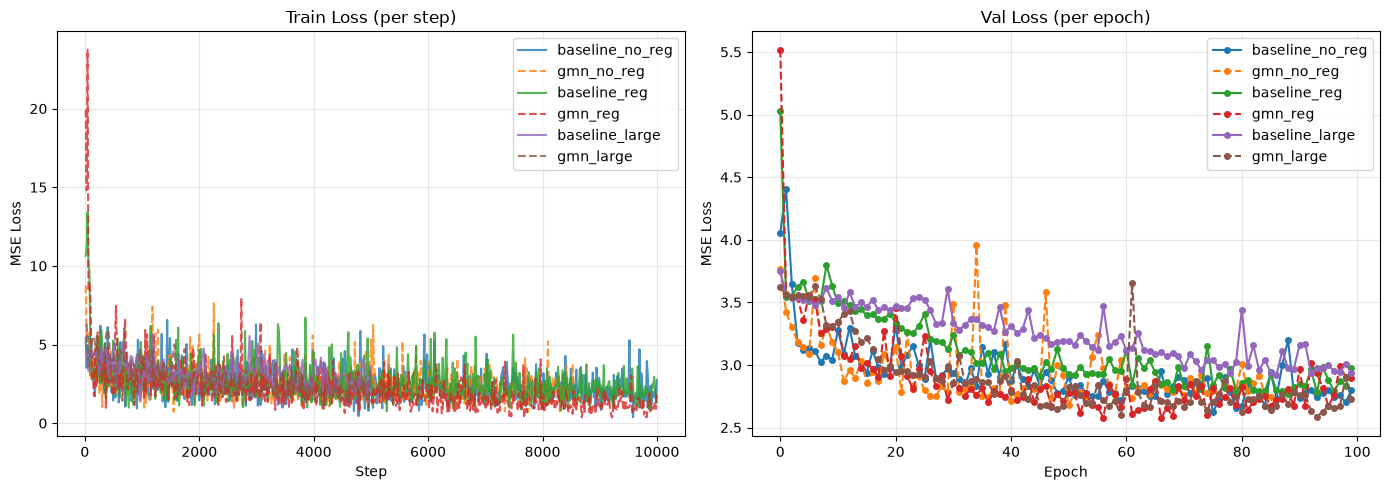

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#on the graph: baseline: solid line, GMN: dashed line
styles = {
    'baseline': {'linestyle': '-'},
    'gmn':      {'linestyle': '--'},
}

for cfg in EXPERIMENTS:
    name = cfg['name']
    if name not in results:
        continue
    metrics = results[name]
    s = styles[cfg['model']]

    train_m = metrics[metrics['train_loss'].notna()]
    val_m   = metrics[metrics['val_loss'].notna()]

    axes[0].plot(train_m['step'], train_m['train_loss'],
                 label=name, alpha=0.8, **s)
    axes[1].plot(val_m['epoch'], val_m['val_loss'],
                 label=name, marker='o', markersize=4, **s)

for ax, title, xlabel in zip(
    axes,
    ['Train Loss (per step)', 'Val Loss (per epoch)'],
    ['Step', 'Epoch'],
):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('MSE Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs(LOGS_DIR, exist_ok=True)
plt.savefig(os.path.join(LOGS_DIR, 'comparison.png'), dpi=150)
plt.show()

In [12]:
summary = []
for cfg in EXPERIMENTS:
    name = cfg['name']
    if name not in results:
        continue
    best_val = results[name]['val_loss'].dropna().min()
    stopped_at = int(results[name]['epoch'].max())
    summary.append({
        'name':               name,
        'model':              cfg['model'],
        'best_val_loss':      round(float(best_val), 4),
        'stopped_epoch':      stopped_at,
        'node_embedding_dims': cfg['node_embedding_dims'][-1],
        'num_layers':         cfg.get('num_layers', 1),
        'normalization':      cfg['normalization'],
        'dropout_p':          cfg['dropout_p'],
        'lr':                 cfg['lr'],
    })

pd.DataFrame(summary).set_index('name').sort_values('best_val_loss')

,model,best_val_loss,stopped_epoch,node_embedding_dims,num_layers,normalization,dropout_p,lr
name,,,,,,,,
gmn_reg,gmn,2.5756,99,48,1,True,0.0,0.001
gmn_large,gmn,2.5872,99,128,1,True,0.4,0.001
baseline_no_reg,baseline,2.6219,99,48,1,False,0.0,0.001
gmn_no_reg,gmn,2.6804,85,48,1,False,0.0,0.001
baseline_reg,baseline,2.7647,99,48,1,True,0.0,0.001
baseline_large,baseline,2.9210,99,128,1,True,0.4,0.001
